In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import (
    COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, PASTEL_CMAP_SEQ, pick_spread, set_font_size,
    ALIGNED_FIG_W, ALIGNED_FONT_SIZE, ALIGNED_LEGEND_FONT_SIZE,
    ALIGNED_LEFT, ALIGNED_RIGHT, ALIGNED_CBAR_FRACTION, ALIGNED_CBAR_PAD, ALIGNED_CBAR_WIDTH_IN,
)
GRID = False

# Linear Spring — Force Saturation vs. Stiffness

`k2_18.npz` + `k20_35.npz` — a single tip spring (`lin_seg3`) swept across k ≈ 1.7–35 N/m,
combined into one continuous sweep (the two k=17/18 N/m points already covered by
`k2_18.npz` are trimmed from `k20_35.npz` before concatenation). For each k, the reference
steps out from x=0 to x=−25 cm; only the outward sweep is kept for this analysis.

**Goal:** shear force (load cell) and apparent stiffness F/x vs. reference position,
colored by k (blue → red), to show where the motors' torque limit starts capping the
achievable spring force.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.ticker import FormatStrFormatter

# ── Load both files ───────────────────────────────────────────────────────────
d1 = {k: v for k, v in np.load('outputs/k_saturation/k2_18.npz',   allow_pickle=True).items()}
d2 = {k: v for k, v in np.load('outputs/k_saturation/k20_35.npz', allow_pickle=True).items()}

# Trim d2: remove k=17 and k=18 (already covered by d1)
k2 = d2['k_params'][:, 0]
keep2 = ~np.isin(np.round(k2, 1), [16.7, 18.3])
d2_trim = {key: val[keep2] if (np.ndim(val) > 0 and val.shape[0] == len(k2)) else val
           for key, val in d2.items()}
print(f'd1 samples: {len(d1["t"]):,}')
print(f'd2 trimmed: {keep2.sum():,} / {len(k2):,} (removed k=17,18)')

# Combine — offset d2 time so it continues after d1
t_offset = d1['t'][-1] + (d1['t'][-1] - d1['t'][-2])
combined = {}
for key in d1:
    a, b = d1[key], d2_trim[key]
    if np.ndim(a) == 0:   # scalar metadata → keep from d1
        combined[key] = a
    elif key == 't':
        combined[key] = np.concatenate([a, b + t_offset])
    else:
        combined[key] = np.concatenate([a, b], axis=0)

t      = combined['t']
k_all  = combined['k_params'][:, 0]
goal_x = combined['goal'][:, 0, 0]
force  = combined['force'] * 9.80665e-3   # load cell outputs GRAMS -> convert to Newtons

k_unique_test = sorted([kv for kv in np.unique(np.round(k_all, 1)) if kv != 66.7])
print(f'\nCombined samples: {len(t):,}')
print(f'Test k values ({len(k_unique_test)}): {k_unique_test}')

d1 samples: 442,636
d2 trimmed: 170,391 / 202,167 (removed k=17,18)

Combined samples: 613,027
Test k values (36): [1.7, 2.3, 3.0, 3.7, 4.3, 5.0, 5.7, 6.3, 7.0, 7.7, 8.3, 9.0, 9.7, 10.3, 11.0, 11.7, 12.3, 13.0, 13.7, 14.3, 15.0, 15.7, 16.3, 17.0, 17.7, 18.3, 20.0, 21.7, 23.3, 25.0, 26.7, 28.3, 30.0, 31.7, 33.3, 35.0]


In [3]:
# ── Extract MOVING_OUT intervals for each k ───────────────────────────────────
# Strategy: within each contiguous segment at k=test_k,
# the ref goes 0→-25cm (MOVING_OUT) then -25cm→0 (MOVING_BACK).
# Split at the minimum of goal_x to isolate only the outward sweep.

segments = {}   # k_value → list of (goal_x_out, force_out) arrays

k_rounded = np.round(k_all, 1)

for kv in k_unique_test:
    in_seg = k_rounded == kv
    # find contiguous blocks
    changes = np.diff(in_seg.astype(int))
    starts  = np.where(changes == 1)[0] + 1
    ends    = np.where(changes == -1)[0] + 1
    if in_seg[0]:  starts = np.concatenate([[0], starts])
    if in_seg[-1]: ends   = np.concatenate([ends, [len(in_seg)]])

    segs_kv = []
    for s, e in zip(starts, ends):
        gx = goal_x[s:e]
        f  = force[s:e]
        if len(gx) < 5:
            continue
        # find where goal_x is minimum (end of outward sweep)
        split = int(np.argmin(gx))
        if split < 3:   # degenerate segment, skip
            continue
        # keep only the outward portion (0 → -25cm)
        segs_kv.append((gx[:split+1], f[:split+1]))
    segments[kv] = segs_kv

valid_k = [kv for kv in k_unique_test if segments[kv]]
print(f'Extracted segments for {len(valid_k)} k values')
for kv in valid_k:
    print(f'  k={kv:.0f}: {len(segments[kv])} sweep(s)')

# Subset of k values actually drawn in the plots below, spread across the full
# tested range (colorbar/normalization still uses the full valid_k range).
N_LINES = 10   # TUNE THIS: number of k traces to show per graph
SPREAD_BIAS = 0.6   # TUNE THIS: <1 concentrates more traces toward high k (where saturation shows), >1 toward low k
plot_k = pick_spread(valid_k, N_LINES, bias=SPREAD_BIAS)
print(f'\nPlotting {len(plot_k)} of {len(valid_k)} k values: {[round(kv, 1) for kv in plot_k]}')

Extracted segments for 36 k values
  k=2: 1 sweep(s)
  k=2: 1 sweep(s)
  k=3: 1 sweep(s)
  k=4: 1 sweep(s)
  k=4: 1 sweep(s)
  k=5: 1 sweep(s)
  k=6: 1 sweep(s)
  k=6: 1 sweep(s)
  k=7: 1 sweep(s)
  k=8: 1 sweep(s)
  k=8: 1 sweep(s)
  k=9: 1 sweep(s)
  k=10: 1 sweep(s)
  k=10: 1 sweep(s)
  k=11: 1 sweep(s)
  k=12: 1 sweep(s)
  k=12: 1 sweep(s)
  k=13: 1 sweep(s)
  k=14: 1 sweep(s)
  k=14: 1 sweep(s)
  k=15: 1 sweep(s)
  k=16: 1 sweep(s)
  k=16: 1 sweep(s)
  k=17: 1 sweep(s)
  k=18: 1 sweep(s)
  k=18: 1 sweep(s)
  k=20: 1 sweep(s)
  k=22: 1 sweep(s)
  k=23: 1 sweep(s)
  k=25: 1 sweep(s)
  k=27: 1 sweep(s)
  k=28: 1 sweep(s)
  k=30: 1 sweep(s)
  k=32: 1 sweep(s)
  k=33: 1 sweep(s)
  k=35: 1 sweep(s)

Plotting 10 of 36 k values: [1.7, 7.7, 11.0, 13.7, 16.3, 18.3, 21.7, 26.7, 31.7, 35.0]


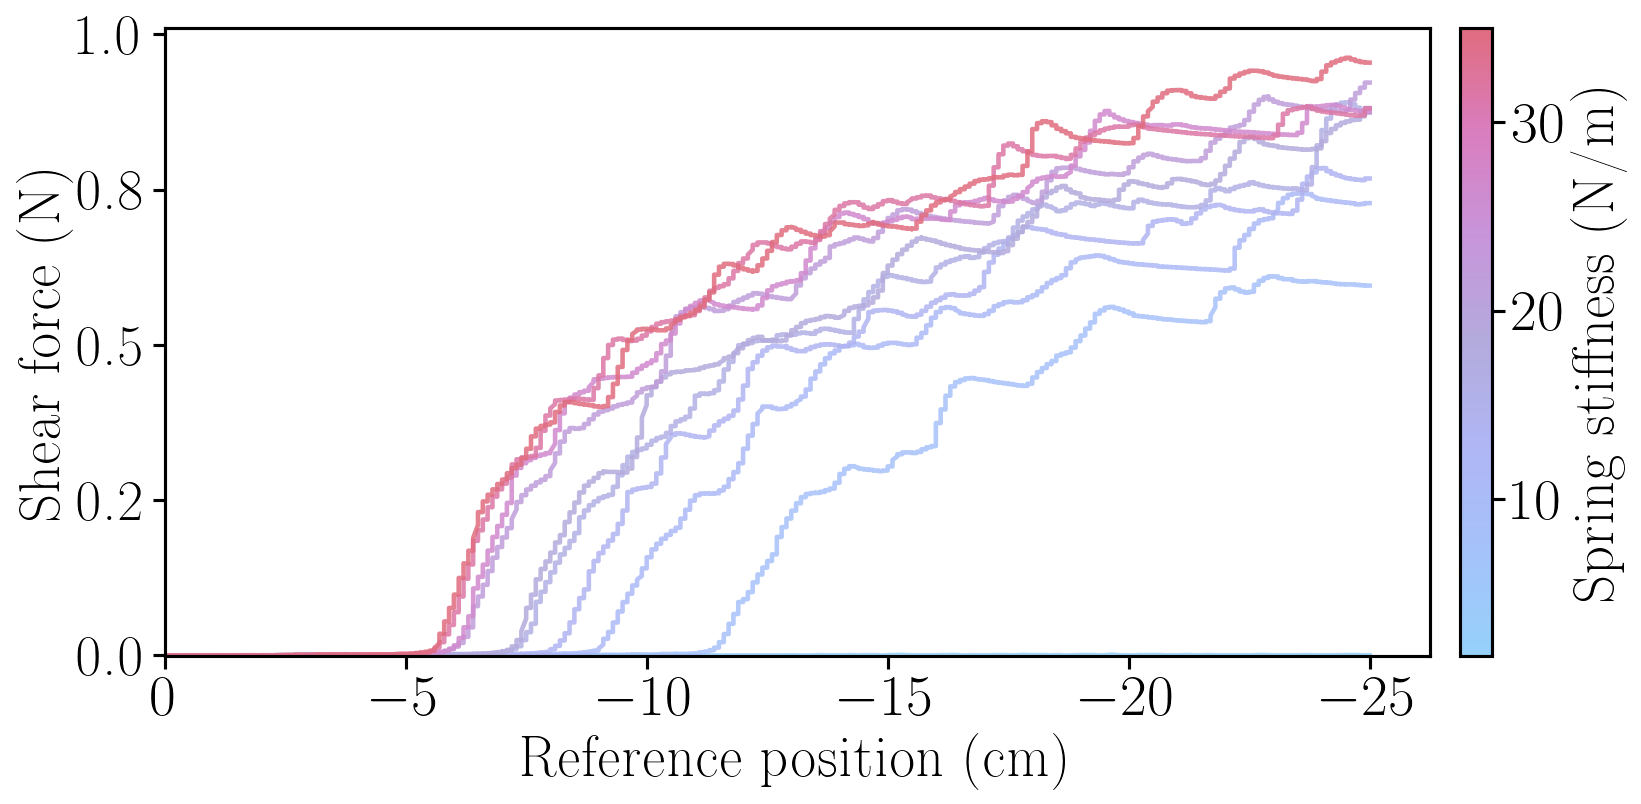

[OK] Saved -> outputs/k_saturation/force_vs_pos_by_k.pdf


In [4]:
# ── Plot: shear force vs ref position, coloured by k ─────────────────────────
# Colormap: cold (blue, light) for low k -> hot (red, dark) for high k --
# sequential (monotonic lightness), not diverging, so no value in the middle
# of the range washes out against the white page.

norm   = mcolors.Normalize(vmin=min(valid_k), vmax=max(valid_k))
cmap   = PASTEL_CMAP_SEQ

# ---- size / aspect for THIS graph only ----
W_IN = 12.0   # in -- TUNE THIS: figure width
ASPECT_W, ASPECT_H = 2, 1   # TUNE THIS: width:height ratio, as two integers
H_IN = W_IN * ASPECT_H / ASPECT_W

FONT_SIZE = 28   # TUNE THIS: axis label / tick / colorbar text size for this graph
LEGEND_FONT_SIZE = FONT_SIZE * 0.75  # TUNE THIS: legend text size only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

fig, ax = plt.subplots(figsize=(W_IN, H_IN))

all_gx_cm, all_f = [], []
for kv in plot_k:
    color = cmap(norm(kv))
    for idx, (gx, f) in enumerate(segments[kv]):
        label = f'K={kv:.0f}' if idx == 0 else None
        ax.plot(gx * 100, f, color=color, linewidth=2.2,
                alpha=0.85, label=label)
        all_gx_cm.append(gx * 100)
        all_f.append(f)
all_gx_cm = np.concatenate(all_gx_cm)
all_f = np.concatenate(all_f)

# Colorbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Spring stiffness (N/m)')

ax.set_xlabel('Reference position (cm)')
ax.set_ylabel('Shear force (N)')
ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
ax.grid(GRID)
# Anchor at x=0 (sweep start) with 0 on the left; data goes negative (outward
# sweep to -25cm), so set_xlim(left=0, right=<negative>) both anchors the
# origin and reproduces the desired 0-on-left / -25-on-right orientation
# without a separate invert_xaxis() call.
ax.set_xlim(0, all_gx_cm.min() * 1.05)
ax.set_ylim(min(0, all_f.min() * 1.05), all_f.max() * 1.05)

plt.tight_layout()
plt.savefig('outputs/k_saturation/force_vs_pos_by_k.pdf')
plt.show()
print('[OK] Saved -> outputs/k_saturation/force_vs_pos_by_k.pdf')

Apparent stiffness = |measured shear force| / |reference displacement|, i.e. |F(x) / x| in N/m -- the secant slope from the origin to each point on the force-vs-position curve above, not a local derivative. Displacement is measured in cm but converted to meters here (x100) so the result is in N/m, directly comparable to the nominal spring stiffness k on the colorbar. Points with |x| < X_MIN_CM are skipped to avoid dividing by ~0, and the absolute value is taken so stiffness reads as a magnitude: during the outward sweep F and x have opposite signs, so the plain ratio F/x would otherwise be negative.


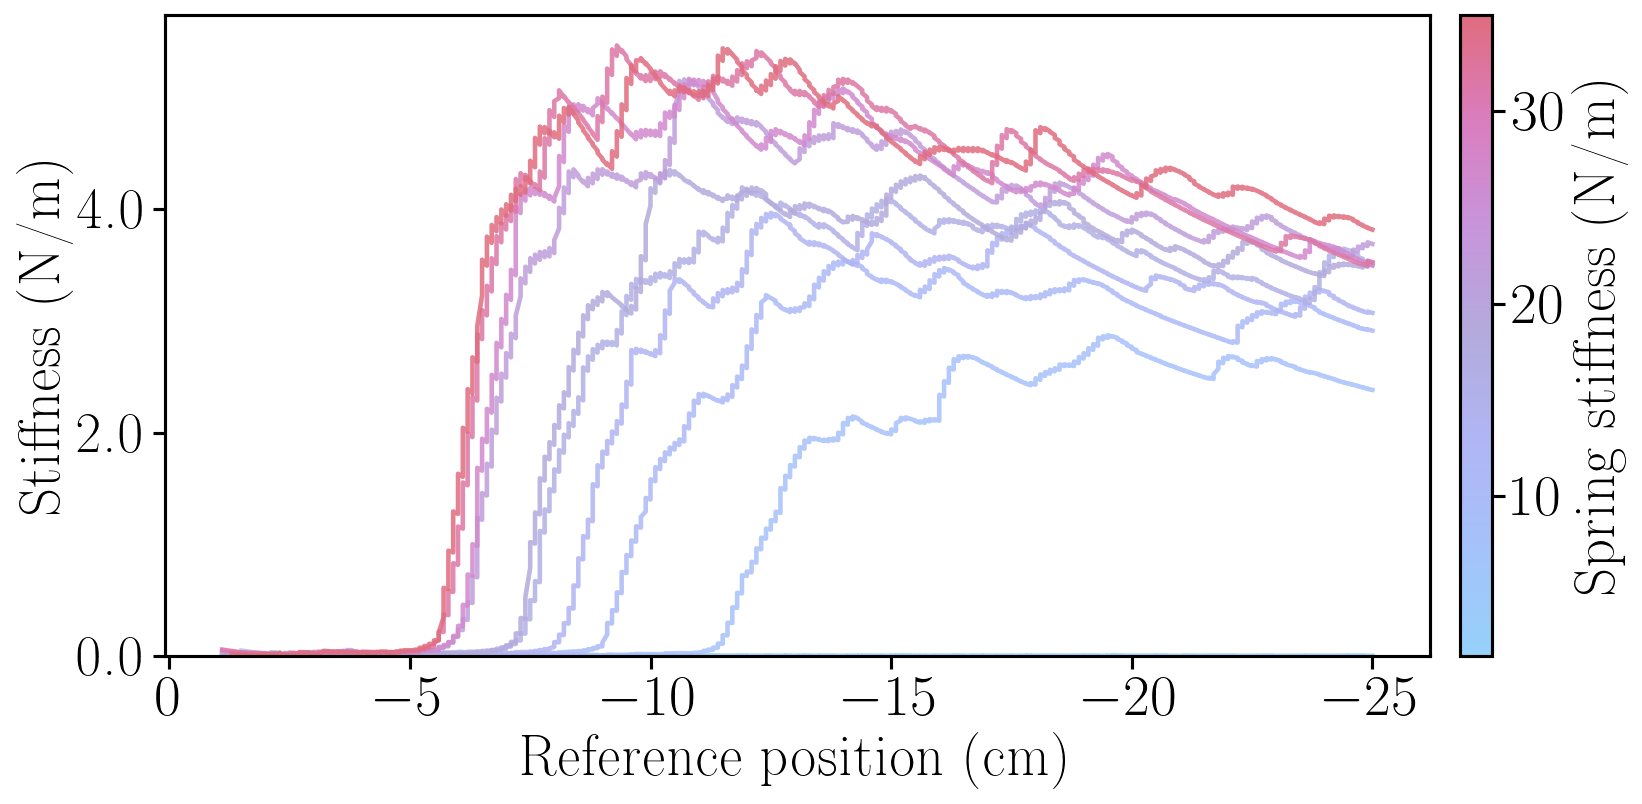

[OK] Saved -> outputs/k_saturation/stiffness_vs_pos_by_k.pdf


In [5]:
# ── Plot: F/x vs x (apparent stiffness) coloured by k ────────────────────────
# Skip points where |x| < X_MIN_CM to avoid division-by-zero near origin
X_MIN_CM = 0.5   # [cm]  ignore first 0.5 cm

print("Apparent stiffness = |measured shear force| / |reference displacement|, "
      "i.e. |F(x) / x| in N/m -- the secant slope from the origin to each point "
      "on the force-vs-position curve above, not a local derivative. Displacement "
      "is measured in cm but converted to meters here (x100) so the result is in "
      "N/m, directly comparable to the nominal spring stiffness k on the colorbar. "
      "Points with |x| < X_MIN_CM are skipped to avoid dividing by ~0, and the "
      "absolute value is taken so stiffness reads as a magnitude: during the "
      "outward sweep F and x have opposite signs, so the plain ratio F/x would "
      "otherwise be negative.")

norm = mcolors.Normalize(vmin=min(valid_k), vmax=max(valid_k))
cmap = PASTEL_CMAP_SEQ

# ---- size / aspect for THIS graph only ----
W_IN = 12.0   # in -- TUNE THIS: figure width
ASPECT_W, ASPECT_H = 2, 1   # TUNE THIS: width:height ratio, as two integers
H_IN = W_IN * ASPECT_H / ASPECT_W

FONT_SIZE = 28   # TUNE THIS: axis label / tick / colorbar text size for this graph
LEGEND_FONT_SIZE = FONT_SIZE * 0.75  # TUNE THIS: legend text size only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

fig, ax = plt.subplots(figsize=(W_IN, H_IN))

for kv in plot_k:
    color = cmap(norm(kv))
    for idx, (gx, f) in enumerate(segments[kv]):
        x_cm = gx * 100          # convert to cm
        mask = np.abs(x_cm) >= X_MIN_CM
        xm, fm = x_cm[mask], f[mask]
        if len(xm) < 2:
            continue
        ratio = np.abs(fm / xm) * 100   # |F/x|, cm -> m -- stiffness magnitude [N/m]
        label = f'K={kv:.0f}' if idx == 0 else None
        ax.plot(xm, ratio, color=color, linewidth=2.2, alpha=0.85, label=label)

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Spring stiffness (N/m)')

ax.set_xlabel('Reference position (cm)')
ax.set_ylabel('Stiffness (N/m)')
ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
ax.set_ylim(0, None)
ax.grid(GRID)
ax.invert_xaxis()

plt.tight_layout()
plt.savefig('outputs/k_saturation/stiffness_vs_pos_by_k.pdf')
plt.show()
print('[OK] Saved -> outputs/k_saturation/stiffness_vs_pos_by_k.pdf')

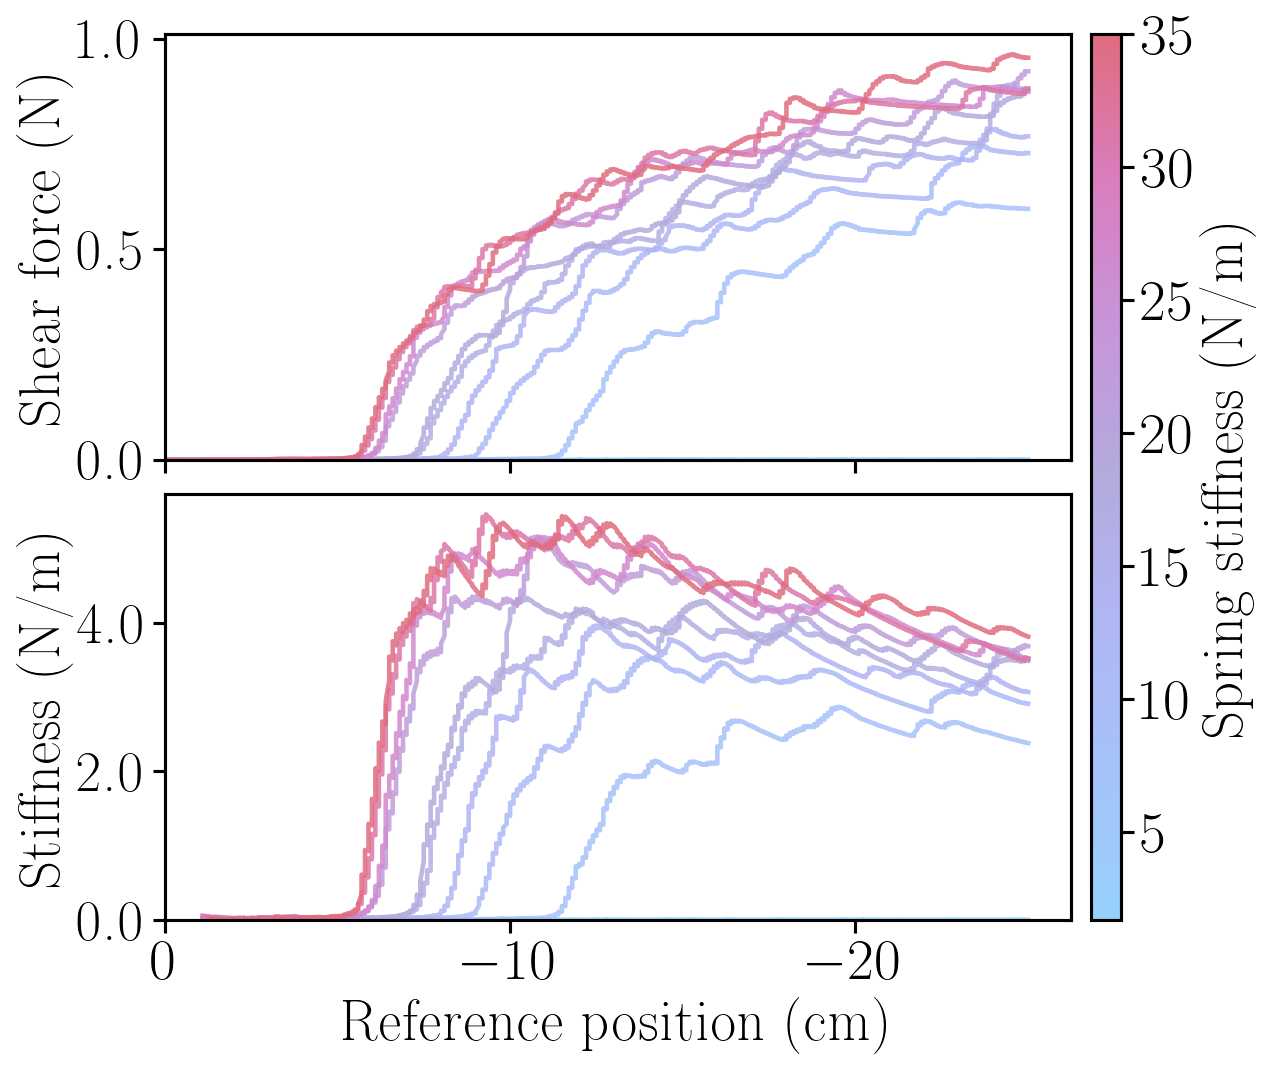

[OK] Saved -> outputs/k_saturation/force_and_stiffness_by_k.pdf


In [6]:
# ── Stacked figure: shear force (top) + stiffness (bottom), sharing one x-axis ──
# Same data/colors as the two figures above, just combined so the reference
# position only needs labeling once (it's shared by both panels).
#
# Sized and margined via the ALIGNED_* constants in plot_config.py -- shared
# with plot_disturbance.ipynb's response figure -- so the two figures can be
# stacked into one multi-panel figure with matching width, font size, and
# colorbar geometry (fraction/pad identical -> identical colorbar width and
# horizontal placement in inches, since both figures use the same total width
# and the same left/right axes fractions).

W_IN = ALIGNED_FIG_W
H_IN = 7.2   # in -- TUNE THIS: total height for the 2 stacked panels

FONT_SIZE = ALIGNED_FONT_SIZE
LEGEND_FONT_SIZE = ALIGNED_LEGEND_FONT_SIZE
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

fig, (ax_f, ax_k) = plt.subplots(2, 1, figsize=(W_IN, H_IN), sharex=True)
fig.subplots_adjust(left=ALIGNED_LEFT, right=ALIGNED_RIGHT, top=0.96, bottom=0.14, hspace=0.08)

for kv in plot_k:
    color = cmap(norm(kv))
    for gx, f in segments[kv]:
        x_cm = gx * 100
        ax_f.plot(x_cm, f, color=color, linewidth=2.2, alpha=0.85)

        mask = np.abs(x_cm) >= X_MIN_CM
        xm, fm = x_cm[mask], f[mask]
        if len(xm) < 2:
            continue
        ax_k.plot(xm, np.abs(fm / xm) * 100, color=color, linewidth=2.2, alpha=0.85)

ax_f.set_ylabel('Shear force (N)')
ax_f.set_ylim(min(0, all_f.min() * 1.05), all_f.max() * 1.05)
ax_f.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
ax_f.grid(GRID)

ax_k.set_ylabel('Stiffness (N/m)')
ax_k.set_ylim(0, None)
ax_k.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
ax_k.grid(GRID)

ax_k.set_xlabel('Reference position (cm)')   # shared axis -- labeled once, on the bottom panel
ax_k.set_xlim(0, all_gx_cm.min() * 1.05)        # 0 on left, -25 on right -- shared via sharex

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
# aspect: this colorbar spans both stacked panels (taller than
# plot_disturbance.ipynb's single-panel one), so it needs a larger
# aspect value to come out the same physical thickness -- see
# ALIGNED_CBAR_WIDTH_IN in plot_config.py.
cbar_height_in = (0.96 - 0.14) * H_IN
cbar = fig.colorbar(sm, ax=[ax_f, ax_k], fraction=ALIGNED_CBAR_FRACTION, pad=ALIGNED_CBAR_PAD,
                    aspect=cbar_height_in / ALIGNED_CBAR_WIDTH_IN)
cbar.set_label('Spring stiffness (N/m)')

# Full (non-tight) canvas so the deliberately-matched axes/colorbar geometry
# survives to the saved file -- 'tight' bbox (the repo default) would crop
# each figure to its own content and silently break the alignment with
# plot_disturbance.ipynb's response figure.
with plt.rc_context({'savefig.bbox': None}):
    fig.savefig('outputs/k_saturation/force_and_stiffness_by_k.pdf')
plt.show()
print('[OK] Saved -> outputs/k_saturation/force_and_stiffness_by_k.pdf')